# Large-scale test: are regimes recoverable from a linear-predictor LeJEPA with $d=124$?

Companion to `regime_separation_tests.ipynb`. That notebook tests the proposal's claims one at a time on small,
clean-cut generators. Here everything is switched on at once, at scale, and trained for a long time. The question is
the practical one: **after self-supervised training, can the regimes be recovered from the latent?**

**Latent process (19 dimensions, sample level, all unit variance).**
* *Regime-dependent:* a 6-D state in three rotation planes. Each of 4 regimes sets every plane's frequency and
  damping (three regimes are permutations of the same frequencies, so they differ only in *which subspace* turns how
  fast). The state is carried across switches. The regime switches at window boundaries, Markov with $p_{\text{stay}}=0.9$.
  **There is no regime cue**: the regime is visible only through the dynamics inside each window.
* *Regime-independent, of different types:* 3 slow AR factors (window autocorrelation 0.9/0.95/0.97, the SFA-type
  competitors of §7); 2 fixed-frequency oscillators (rotation-like, which favour separate encoders, §5); stochastic
  volatility (information only in second moments); a multiplicative sensor-gain drift (λ = 0.98); 4 white
  distractors and heavy-tailed bursts (unpredictable).

**Corruption to 128 channels**, aggressive but recoverable: an injective linear up-projection, 4 random **invertible**
affine coupling layers (RealNVP-style), soft saturation, the multiplicative gain drift, per-channel first-order
sensor dynamics within each window, then Gaussian noise, 1 % outliers and 5 % channels missing per window. Training
windows are **rendered on the fly** on the GPU, so the model never sees the same noise twice.

**Model.** TCN backbone (width 256, 5 dilated residual levels) + le-wm projector → $d=124$ for each encoder. Linear
predictor, SIGReg (verbatim from le-wm, λ = 0.1), one penalty per encoder. Shared and separate designs, 20 000 steps
each.

**Readouts.** Linear / MLP probes, unsupervised GMM on PCA of $Z$ (with and without temporal smoothing),
a switching regression on the top canonical pairs between $Z$ and $Y$ (separate design), and the linear $R^2$ of
every ground-truth feature type, to see *what* the 124 dimensions were spent on. The baselines are raw window statistics, the
same encoder untrained, and a supervised ceiling.

## Setup (shared helpers are the same code as in the small-scale notebook)

In [9]:
import os
for _v in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ.setdefault(_v, "4")      # small matrices: many threads only oversubscribe the CPU
import math, time, itertools, warnings
from dataclasses import dataclass, field, replace
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neural_network import MLPClassifier
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print('device:', DEVICE)

device: mps


In [10]:
FAST = False
EMBED_DIM = 124                      # latent dimension d of each encoder ("hidden dim 124")
HIDDEN = 256                         # backbone width
STEPS = 2000 if FAST else 20000      # long run
BATCH = 256
LR = 1e-3
LAM = 0.1                            # SIGReg weight (λ=0.1 reached the theory in the small notebook; λ=1 stalled)
EVAL_EVERY = 500 if FAST else 2000   # learning-curve checkpoints
SERIES = (8, 4) if FAST else (64, 16)
T_WIN = 1000 if FAST else 2000       # windows per series
OUT = "large_scale_runs"             # checkpoints + results (re-running loads them instead of retraining)
import os, json, pickle
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
os.makedirs(OUT, exist_ok=True)
C_SH, C_SEP, C_TH, C_B = "#2a78d6", "#eb6834", "#52514e", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 2, "figure.dpi": 110, "font.size": 9})

In [11]:
class SIGReg(torch.nn.Module):
    """Sketch Isotropic Gaussian Regularizer (single-GPU!)

    Verbatim from lucas-maes/le-wm, module.py (the LeWM implementation of LeJEPA's SIGReg):
    Epps-Pulley test of every random 1-D projection against N(0,1), on 17 knots in [0,3].
    """

    def __init__(self, knots=17, num_proj=1024):
        super().__init__()
        self.num_proj = num_proj
        t = torch.linspace(0, 3, knots, dtype=torch.float32)
        dt = 3 / (knots - 1)
        weights = torch.full((knots,), 2 * dt, dtype=torch.float32)
        weights[[0, -1]] = dt
        window = torch.exp(-t.square() / 2.0)
        self.register_buffer("t", t)
        self.register_buffer("phi", window)
        self.register_buffer("weights", weights * window)

    def forward(self, proj):
        """
        proj: (T, B, D)
        """
        # sample random projections
        A = torch.randn(proj.size(-1), self.num_proj, device=proj.device)
        A = A.div_(A.norm(p=2, dim=0))
        # compute the epps-pulley statistic
        x_t = (proj @ A).unsqueeze(-1) * self.t
        err = (x_t.cos().mean(-3) - self.phi).square() + x_t.sin().mean(-3).square()
        statistic = (err @ self.weights) * proj.size(-2)
        return statistic.mean()  # average over projections and time


def batch_whiten(z, eps=1e-4):
    """Exact (in-batch) Cholesky whitening: the idealised constraint of the theory (W-MSE / VAMPnet style)."""
    zc = z - z.mean(0, keepdim=True)
    cov = zc.T @ zc / (z.shape[0] - 1) + eps * torch.eye(z.shape[1], device=z.device)
    L = torch.linalg.cholesky(cov.cpu()).to(z.device)  # cholesky is not implemented on MPS
    return torch.linalg.solve_triangular(L, zc.T, upper=False).T

In [12]:
def predictable_variance(Z, Y, shared):
    """||C||_F^2 with C = E[Y_{t+1} Z_t^T] after exact (empirical) whitening of each encoder's outputs.
    For the shared design the same whitening map is used for both sides (it is one encoder)."""
    d = Z.shape[-1]
    if shared:
        Wd = whiten_map(Z.reshape(-1, d))
        Zw = Yw = (Z - Z.reshape(-1, d).mean(0)) @ Wd
    else:
        Zw = (Z - Z.reshape(-1, d).mean(0)) @ whiten_map(Z.reshape(-1, d))
        Yw = (Y - Y.reshape(-1, d).mean(0)) @ whiten_map(Y.reshape(-1, d))
    a, b = Zw[:, :-1].reshape(-1, Zw.shape[-1]), Yw[:, 1:].reshape(-1, Yw.shape[-1])
    C = b.T @ a / len(a)
    return float((C ** 2).sum()), np.linalg.svd(C, compute_uv=False)


def whiten_map(A, eps=1e-6):
    A = A - A.mean(0)
    C = A.T @ A / len(A)
    w, V = np.linalg.eigh(C)
    w = np.maximum(w, eps * max(w.max(), eps))
    return V / np.sqrt(w)


def gt_features(spec, lat):
    """Named ground-truth features per window, each (N,T,k). These are the candidate features of the theory."""
    S, x, n = lat["S"], lat["x"], lat["n"]
    K, pi = spec.K, spec.pi
    onehot = np.eye(K)[S]
    f = {"regime": onehot[..., : K - 1]} if K > 1 else {}
    f["x"] = x
    f["g (x·1[S=k])"] = np.concatenate([x * onehot[..., k: k + 1] / math.sqrt(pi[k]) for k in range(K)], -1)
    f["|x|²"] = (x ** 2).sum(-1, keepdims=True)
    if spec.m == 2:
        f["x quad. (x1²-x2², x1x2)"] = np.stack([x[..., 0] ** 2 - x[..., 1] ** 2, x[..., 0] * x[..., 1]], -1)
    if spec.q:
        f["nuisance n"] = n
        quad = [n[..., i] * n[..., j] - (i == j) for i in range(spec.q) for j in range(i, spec.q)]
        f["nuisance n²"] = np.stack(quad, -1)
    return f


def r2_table(Lat, feats, n_fit):
    """Linear R^2 of each ground-truth feature from the latent (fit on first n_fit windows, test on the rest)."""
    out = {}
    L = Lat.reshape(-1, Lat.shape[-1])
    for name, F_ in feats.items():
        Fm = F_.reshape(-1, F_.shape[-1])
        r2s = []
        for j in range(Fm.shape[1]):
            reg = LinearRegression().fit(L[:n_fit], Fm[:n_fit, j])
            res = Fm[n_fit:, j] - reg.predict(L[n_fit:])
            r2s.append(1 - res.var() / (Fm[n_fit:, j].var() + 1e-12))
        out[name] = float(np.clip(np.mean(r2s), 0, 1))
    return out


def best_perm_acc(true, pred, K):
    M = np.zeros((K, K))
    for a, b in zip(true, pred):
        M[a, b] += 1
    r, c = linear_sum_assignment(-M)
    mapping = dict(zip(c, r))
    return balanced_accuracy_score(true, [mapping.get(p, -1) for p in pred])


def switching_regression(X, Y, K, restarts=5, iters=50, seed=0):
    """Unsupervised mixture of K linear regressions Y ~ A_k [X,1] (EM). Returns hard labels."""
    rng = np.random.default_rng(seed)
    N, dy = Y.shape
    Xd = np.c_[X, np.ones(N)]
    best, best_ll = None, -np.inf
    for r in range(restarts):
        R = rng.dirichlet(np.ones(K), N)
        for it in range(iters):
            logp = np.zeros((N, K))
            for k in range(K):
                w = R[:, k] + 1e-9
                A = np.linalg.solve(Xd.T @ (Xd * w[:, None]) + 1e-6 * np.eye(Xd.shape[1]), Xd.T @ (Y * w[:, None]))
                E = Y - Xd @ A
                Sig = (E * w[:, None]).T @ E / w.sum() + 1e-4 * np.eye(dy)
                Si = np.linalg.inv(Sig)
                logp[:, k] = (np.log(w.mean()) - 0.5 * np.linalg.slogdet(Sig)[1]
                              - 0.5 * np.einsum("ni,ij,nj->n", E, Si, E))
            mx = logp.max(1, keepdims=True)
            ll = float((mx[:, 0] + np.log(np.exp(logp - mx).sum(1))).sum())
            R = np.exp(logp - mx); R /= R.sum(1, keepdims=True)
        if ll > best_ll:
            best, best_ll = R.argmax(1), ll
    return best


def regime_readouts(Z, Ysame, S, K, shared, n_fit, seed=0):
    """How the regime can be read out of the latents (balanced accuracy, chance = 1/K)."""
    d = Z.shape[-1]
    Zf, Yf, Sf = Z.reshape(-1, d), Ysame.reshape(-1, d), S.reshape(-1)
    sc = StandardScaler().fit(Zf[:n_fit]); Zs = sc.transform(Zf)
    scy = StandardScaler().fit(Yf[:n_fit]); Ys = scy.transform(Yf)
    out = {}
    lin = LogisticRegression(max_iter=2000).fit(Zs[:n_fit], Sf[:n_fit])
    out["probe lin(Z)"] = balanced_accuracy_score(Sf[n_fit:], lin.predict(Zs[n_fit:]))
    mlp = MLPClassifier((64, 64), max_iter=200, early_stopping=True, random_state=seed).fit(Zs[:n_fit], Sf[:n_fit])
    out["probe MLP(Z)"] = balanced_accuracy_score(Sf[n_fit:], mlp.predict(Zs[n_fit:]))
    gm = GaussianMixture(K, n_init=3, random_state=seed).fit(Zs[:n_fit])
    lab = gm.predict(Zs[n_fit:])
    out["GMM(Z) acc"] = best_perm_acc(Sf[n_fit:], lab, K)
    if not shared:
        mlp = MLPClassifier((64, 64), max_iter=200, early_stopping=True, random_state=seed).fit(Ys[:n_fit], Sf[:n_fit])
        out["probe MLP(Y)"] = balanced_accuracy_score(Sf[n_fit:], mlp.predict(Ys[n_fit:]))
        ZY = np.c_[Zs, Ys]
        mlp = MLPClassifier((64, 64), max_iter=200, early_stopping=True, random_state=seed).fit(ZY[:n_fit], Sf[:n_fit])
        out["probe MLP(Z,Y)"] = balanced_accuracy_score(Sf[n_fit:], mlp.predict(ZY[n_fit:]))
        lab = switching_regression(Zs[n_fit:], Ys[n_fit:], K, seed=seed)
        out["switch-reg(Z→Y)"] = best_perm_acc(Sf[n_fit:], lab, K)
        if d == 1 and K == 2:
            out["sign(z·y)"] = best_perm_acc(Sf[n_fit:], (Zs[n_fit:, 0] * Ys[n_fit:, 0] > 0).astype(int), 2)
    return out


def evaluate_latents(Z, Y, spec, lat, shared, n_eval=8000, seed=0, clusters=True):
    """Z, Y: (N,T,d) context / target-encoder outputs on the SAME windows."""
    score, sv = predictable_variance(Z, Y, shared)
    feats = gt_features(spec, lat)
    N, T, d = Z.shape
    take = min(N * T, n_eval)
    idx = np.random.default_rng(seed).permutation(N * T)[:take]
    sub = lambda A: A.reshape(N * T, -1)[idx][None]
    n_fit = int(0.6 * take)
    fsub = {k: sub(v) for k, v in feats.items()}
    res = dict(score=score, canon=np.round(sv, 3))
    res.update({f"R²Z {k}": v for k, v in r2_table(sub(Z), fsub, n_fit).items()})
    if not shared:
        res.update({f"R²Y {k}": v for k, v in r2_table(sub(Y), fsub, n_fit).items()})
    if spec.K > 1:
        res.update(regime_readouts(sub(Z), sub(Y), sub(lat["S"][..., None])[..., 0], spec.K, shared, n_fit, seed))
        if clusters:
            res.update({f"clu {k}": v for k, v in cluster_battery(Z, lat["S"], spec.K, None if shared else Y, seed=seed).items()})
    cov = np.cov(Z.reshape(-1, d).T).reshape(d, d)
    ev = np.linalg.eigvalsh(cov)
    res["latent cov eig (min,max)"] = (round(float(ev.min()), 2), round(float(ev.max()), 2))
    return res

In [13]:
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA


def _forward_backward(logB, A, pi, lengths):
    """Scaled forward-backward over several sequences. Returns posteriors, expected transition counts, log-lik."""
    N, K = logB.shape
    gamma, xi, ll, start = np.zeros((N, K)), np.zeros((K, K)), 0.0, 0
    for L in lengths:
        lb = logB[start: start + L]
        m = lb.max(1, keepdims=True)
        B = np.exp(lb - m)
        alpha, c = np.zeros((L, K)), np.zeros(L)
        a = pi * B[0]; c[0] = a.sum() + 1e-300; alpha[0] = a / c[0]
        for t in range(1, L):
            a = (alpha[t - 1] @ A) * B[t]; c[t] = a.sum() + 1e-300; alpha[t] = a / c[t]
        beta = np.ones((L, K))
        for t in range(L - 2, -1, -1):
            beta[t] = (A @ (B[t + 1] * beta[t + 1])) / c[t + 1]
        g = alpha * beta
        gamma[start: start + L] = g / g.sum(1, keepdims=True)
        xi += A * (alpha[:-1].T @ (B[1:] * beta[1:] / c[1:, None]))
        ll += np.log(c).sum() + m.sum()
        start += L
    return gamma, xi, ll


def hmm_regression(X, Y, K, lengths, iters=40, restarts=3, seed=0, init=None):
    """HMM whose hidden state k emits Y_t ~ N(A_k [X_t, 1], Σ_k), fitted by Baum-Welch.
    X=None: Gaussian HMM. X=z_t, Y=z_{t+1}: autoregressive HMM (temporal switching regression).
    X=Z, Y=Y on the same input: the switching regression of §6 with a Markov prior on the regime."""
    rng = np.random.default_rng(seed)
    N, dy = Y.shape
    Xd = np.ones((N, 1)) if X is None else np.c_[X, np.ones(N)]
    best, best_ll = None, -np.inf
    for r in range(restarts):
        R = np.eye(K)[init] * 0.8 + 0.2 / K if (r == 0 and init is not None) else rng.dirichlet(np.ones(K), N)
        A = np.full((K, K), 0.1 / max(K - 1, 1)); np.fill_diagonal(A, 0.9)
        pi = np.full(K, 1 / K)
        for it in range(iters):
            logB = np.zeros((N, K))
            for k in range(K):
                w = R[:, k] + 1e-9
                Ak = np.linalg.solve(Xd.T @ (Xd * w[:, None]) + 1e-6 * np.eye(Xd.shape[1]), Xd.T @ (Y * w[:, None]))
                E = Y - Xd @ Ak
                Sig = (E * w[:, None]).T @ E / w.sum() + 1e-4 * np.eye(dy)
                logB[:, k] = -0.5 * np.linalg.slogdet(Sig)[1] - 0.5 * np.einsum("ni,ij,nj->n", E, np.linalg.inv(Sig), E)
            R, xi, ll = _forward_backward(logB, A, pi, lengths)
            A = xi / xi.sum(1, keepdims=True)
        if ll > best_ll:
            best, best_ll = R.argmax(1), ll
    return best


def tsc_cluster(Z, K, q=20, seed=0):
    """Thresholding-based subspace clustering (Heckel & Bölcskei, 2015): each point is linked to its q neighbours in
    absolute cosine similarity, then spectral clustering. Recovers unions of subspaces (regime-specific directions,
    the 'g' features) and is designed for high dimension."""
    Zn = Z - Z.mean(0)
    Zn = Zn / (np.linalg.norm(Zn, axis=1, keepdims=True) + 1e-12)
    C = np.abs(Zn @ Zn.T); np.fill_diagonal(C, 0)
    idx = np.argpartition(-C, q, axis=1)[:, :q]
    rows = np.repeat(np.arange(len(Z)), q)
    vals = np.exp(-2 * np.arccos(np.clip(C[rows, idx.reshape(-1)], 0, 1)))
    from scipy.sparse import csr_matrix
    W = csr_matrix((vals, (rows, idx.reshape(-1))), shape=C.shape)
    W = W + W.T
    return SpectralClustering(K, affinity="precomputed", random_state=seed, assign_labels="cluster_qr").fit_predict(W)


def cluster_battery(Z, S, K, Y=None, n_windows=4000, pcs=8, seed=0):
    """Unsupervised regime recovery from a latent, using contiguous windows (n_series, T, d), so temporal methods apply.
    Every method is scored by balanced accuracy after the best label permutation (chance 1/K)."""
    n_ser = max(1, min(Z.shape[0], int(np.ceil(n_windows / Z.shape[1]))))
    T = min(Z.shape[1], n_windows // n_ser)
    Zc, Sc = Z[:n_ser, :T], S[:n_ser, :T].reshape(-1)
    d = Z.shape[-1]
    flat = StandardScaler().fit_transform(Zc.reshape(-1, d))
    k = min(d, pcs)
    P = PCA(k, whiten=True, random_state=seed).fit_transform(flat) if d > k else flat
    out = {}
    gm = GaussianMixture(K, n_init=3, random_state=seed).fit(P)
    g_lab = gm.predict(P)
    out["GMM"] = best_perm_acc(Sc, g_lab, K)
    out["spectral kNN"] = best_perm_acc(Sc, SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=15,
                                                               random_state=seed, assign_labels="cluster_qr").fit_predict(P), K)
    if d >= 2:
        out["subspace (TSC)"] = best_perm_acc(Sc, tsc_cluster(flat, K, seed=seed), K)
    lengths = [T] * n_ser
    out["HMM"] = best_perm_acc(Sc, hmm_regression(None, P, K, lengths, seed=seed, init=g_lab), K)
    Pm = P.reshape(n_ser, T, -1)
    X_ar, Y_ar = Pm[:, :-1].reshape(-1, k), Pm[:, 1:].reshape(-1, k)
    S_ar = S[:n_ser, :T - 1].reshape(-1)          # S_t governs z_t -> z_{t+1}
    init_ar = g_lab.reshape(n_ser, T)[:, :-1].reshape(-1)
    out["AR-HMM (z_t→z_t+1)"] = best_perm_acc(S_ar, hmm_regression(X_ar, Y_ar, K, [T - 1] * n_ser, seed=seed, init=init_ar), K)
    if Y is not None:
        Yf = StandardScaler().fit_transform(Y[:n_ser, :T].reshape(-1, d))
        Q = PCA(k, whiten=True, random_state=seed).fit_transform(Yf) if d > k else Yf
        out["HMM switch-reg (Z→Y)"] = best_perm_acc(Sc, hmm_regression(P, Q, K, lengths, seed=seed), K)
    return out

In [14]:
def oracle_dictionary(spec, lat, deg=3):
    """Phi_oracle: all monomials (degree <= deg) of the true state and nuisance factors, each also multiplied by every
    regime indicator, plus the indicators. A linear encoder on this Phi is the setting of the proposal."""
    S, x, n = lat["S"], lat["x"], lat["n"]
    v = np.concatenate([x, n], -1)
    nv = v.shape[-1]
    monos = []
    for dgr in range(1, deg + 1):
        for comb in itertools.combinations_with_replacement(range(nv), dgr):
            monos.append(np.prod(v[..., list(comb)], -1))
    monos = np.stack(monos, -1)
    onehot = np.eye(spec.K)[S]
    parts = [onehot[..., : spec.K - 1]] + [monos * onehot[..., k: k + 1] for k in range(spec.K)]
    return np.concatenate(parts, -1)


def oracle_K(Phi):
    N, T, Fd = Phi.shape
    flat = Phi.reshape(-1, Fd)
    mu = flat.mean(0)
    C = (flat - mu).T @ (flat - mu) / len(flat)
    w, V = np.linalg.eigh(C)
    keep = w > 1e-7 * w.max()
    Wh = V[:, keep] / np.sqrt(w[keep])
    Pw = (Phi - mu) @ Wh
    a, b = Pw[:, :-1].reshape(-1, Wh.shape[1]), Pw[:, 1:].reshape(-1, Wh.shape[1])
    return b.T @ a / len(a), Pw


def shared_optimum(K, d, iters=400, lr=0.2, seed=0):
    """max_U ||U^T K U||_F^2 on the Stiefel manifold (Riemannian ascent, several starts)."""
    rng = np.random.default_rng(seed)
    Ks = (K + K.T) / 2
    w, V = np.linalg.eigh(Ks)
    starts = [V[:, np.argsort(-abs(w))[:d]]]
    Uk, sk, Vkt = np.linalg.svd(K)
    starts += [Uk[:, :d], Vkt[:d].T, np.linalg.qr(Uk[:, :d] + Vkt[:d].T)[0]]
    starts += [np.linalg.qr(rng.standard_normal((K.shape[0], d)))[0] for _ in range(4)]
    best, bestU = -1, None
    for U in starts:
        for _ in range(iters):
            C = U.T @ K @ U
            G = 2 * (K @ U @ C.T + K.T @ U @ C)
            G = G - U @ (U.T @ G + G.T @ U) / 2
            U, _ = np.linalg.qr(U + lr * G)
        f = float(((U.T @ K @ U) ** 2).sum())
        if f > best:
            best, bestU = f, U
    lower = float(np.sum(np.sort(w ** 2)[::-1][:d]))
    upper = float(np.sum(sk[:d] ** 2))
    return best, bestU, lower, upper


def oracle_analysis(spec, d_list, n_series=40, T=2500, seed=123, deg=3, readouts=True):
    """Theory prediction: optimal linear encoders on Phi_oracle (exact whitening, population ~ long simulation)."""
    rng = np.random.default_rng(seed)
    lat = simulate_latents(spec, n_series, T, rng)
    Phi = oracle_dictionary(spec, lat, deg)
    K, Pw = oracle_K(Phi)
    Uk, sk, Vkt = np.linalg.svd(K)
    rows = []
    for d in d_list:
        f_sh, U, lo, up = shared_optimum(K, d)
        for design in ["shared", "separate"]:
            if design == "shared":
                Zc = Yc = Pw @ U
                row = dict(design=design, d=d, score=f_sh, bracket=(round(lo, 3), round(up, 3)))
            else:
                Zc, Yc = Pw @ Vkt[:d].T, Pw @ Uk[:, :d]
                row = dict(design=design, d=d, score=float(np.sum(sk[:d] ** 2)))
            if readouts:
                ev = evaluate_latents(Zc, Yc, spec, lat, design == "shared", seed=seed, clusters=False)
                ev.pop("score"); ev.pop("latent cov eig (min,max)")
                row.update(ev)
            rows.append(row)
    return pd.DataFrame(rows)

## Generator and corruption

In [15]:
@dataclass
class BigSpec:
    K: int = 4
    p_stay: float = 0.9
    W: int = 32                                   # samples per window
    D: int = 128                                  # observed channels
    # regime-dependent state: 3 rotation planes; regime k sets each plane's frequency (cycles/sample) and damping
    reg_freqs: tuple = ((0.05, 0.12, 0.20), (0.12, 0.20, 0.05), (0.20, 0.05, 0.12), (0.08, 0.16, 0.26))
    reg_damp: tuple = (0.99, 0.99, 0.99, 0.97)
    # regime-independent features of different types
    slow_lams: tuple = (0.9, 0.95, 0.97)          # slow AR factors (window-level autocorrelation)
    osc_freqs: tuple = (0.03, 0.31)               # fixed-frequency oscillators (2 planes)
    osc_damp: float = 0.995
    vol_lam: float = 0.95                         # stochastic volatility (log-vol AR, window-level)
    vol_scale: float = 0.8
    gain_lam: float = 0.98                        # multiplicative sensor-gain drift
    gain_scale: float = 0.25
    n_distract: int = 4                           # white distractors (unpredictable)
    burst_rate: float = 0.02                      # heavy-tailed bursts (unpredictable)
    # corruption
    couplings: int = 4                            # invertible affine coupling layers
    coupling_strength: float = 1.0
    saturation: float = 3.0                       # soft clip a·tanh(o/a)
    lowpass_max: float = 0.6                      # per-channel first-order sensor dynamics within a window
    obs_noise: float = 0.2
    outliers: float = 0.01
    dropout: float = 0.05                         # whole channel missing in a window
    seed: int = 0

    @property
    def n_lat(self):
        return 6 + len(self.slow_lams) + 2 * len(self.osc_freqs) + 1 + self.n_distract + 1


def _rot(f, r):
    a = 2 * np.pi * f
    return r * np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])


def simulate_big(spec, n_series, T, rng):
    """Sample-level latent process. Regimes switch at window boundaries (Markov, p_stay); every component has unit
    stationary variance. Returns per-sample latents u (N,T,W,n_lat), log-gain (N,T,W) and window-level labels."""
    K, W = spec.K, spec.W
    P = np.full((K, K), (1 - spec.p_stay) / (K - 1)); np.fill_diagonal(P, spec.p_stay)
    S = np.zeros((n_series, T), int); S[:, 0] = rng.integers(K, size=n_series)
    cum = P.cumsum(1)
    for t in range(1, T):
        S[:, t] = (rng.random(n_series)[:, None] > cum[S[:, t - 1]]).sum(1)
    B = np.stack([np.block([
        [_rot(spec.reg_freqs[k][0], spec.reg_damp[k]), np.zeros((2, 4))],
        [np.zeros((2, 2)), _rot(spec.reg_freqs[k][1], spec.reg_damp[k]), np.zeros((2, 2))],
        [np.zeros((2, 4)), _rot(spec.reg_freqs[k][2], spec.reg_damp[k])]]) for k in range(K)])
    sd_reg = np.sqrt(1 - np.array(spec.reg_damp) ** 2)
    a_slow = np.array(spec.slow_lams) ** (1 / W)
    Bo = [_rot(f, spec.osc_damp) for f in spec.osc_freqs]
    a_vol, a_gain = spec.vol_lam ** (1 / W), spec.gain_lam ** (1 / W)
    n_s, n_o = len(spec.slow_lams), 2 * len(spec.osc_freqs)
    N, TW = n_series, T * W
    x = rng.standard_normal((N, 6)); slow = rng.standard_normal((N, n_s)); osc = rng.standard_normal((N, n_o))
    h = rng.standard_normal(N); G = rng.standard_normal(N)
    X = np.zeros((N, TW, 6), np.float32); SL = np.zeros((N, TW, n_s), np.float32)
    OS = np.zeros((N, TW, n_o), np.float32); H = np.zeros((N, TW), np.float32); GG = np.zeros((N, TW), np.float32)
    for s in range(TW):
        k = S[:, s // W]
        x = np.einsum("nij,nj->ni", B[k], x) + sd_reg[k][:, None] * rng.standard_normal((N, 6))
        slow = a_slow * slow + np.sqrt(1 - a_slow ** 2) * rng.standard_normal((N, n_s))
        osc = np.concatenate([osc[:, 2 * i: 2 * i + 2] @ Bo[i].T for i in range(len(Bo))], 1) \
            + math.sqrt(1 - spec.osc_damp ** 2) * rng.standard_normal((N, n_o))
        h = a_vol * h + math.sqrt(1 - a_vol ** 2) * rng.standard_normal(N)
        G = a_gain * G + math.sqrt(1 - a_gain ** 2) * rng.standard_normal(N)
        X[:, s], SL[:, s], OS[:, s], H[:, s], GG[:, s] = x, slow, osc, h, G
    vol = np.exp(spec.vol_scale * H - spec.vol_scale ** 2) * rng.standard_normal((N, TW))
    distract = rng.standard_normal((N, TW, spec.n_distract))
    burst = (rng.random((N, TW)) < spec.burst_rate) * rng.standard_t(3, (N, TW)) * 3
    u = np.concatenate([X, SL, OS, vol[..., None], distract, burst[..., None]], -1).astype(np.float32)
    r = lambda A: A.reshape(N, T, W, *A.shape[2:])
    return dict(S=S, u=r(u), logg=r(spec.gain_scale * GG), x=r(X), slow=r(SL), osc=r(OS), h=r(H), G=r(GG))


class Corruptor(nn.Module):
    """Fixed random map latent (n_lat) -> D channels: up-projection, invertible affine couplings, soft saturation,
    multiplicative gain drift, per-channel low-pass sensor dynamics, noise, outliers, channel dropout.
    Everything before the noise is invertible (couplings) or monotone (saturation, gain, causal filter)."""

    def __init__(self, spec):
        super().__init__()
        g = torch.Generator().manual_seed(1000 + spec.seed)
        D, L = spec.D, spec.n_lat
        Q, _ = torch.linalg.qr(torch.randn(D, L, generator=g))
        self.register_buffer("P", Q * math.sqrt(D / L))                    # orthonormal columns -> injective
        self.perms = [torch.randperm(D, generator=g) for _ in range(spec.couplings)]
        h = D // 2
        self.A = nn.ParameterList([nn.Parameter(torch.randn(h, h, generator=g) * 1.5 / math.sqrt(h), requires_grad=False) for _ in range(spec.couplings)])
        self.C = nn.ParameterList([nn.Parameter(torch.randn(h, h, generator=g) * 1.5 / math.sqrt(h), requires_grad=False) for _ in range(spec.couplings)])
        self.register_buffer("alpha", torch.rand(D, generator=g) * spec.lowpass_max)
        self.spec = spec
        self.register_buffer("mu", torch.zeros(D)); self.register_buffer("sd", torch.ones(D))

    def clean(self, u, logg):
        s = self.spec
        o = u @ self.P.T
        h = s.D // 2
        for perm, A, C in zip(self.perms, self.A, self.C):
            o = o[..., perm.to(o.device)]
            a, b = o[..., :h], o[..., h:]
            b = b * torch.exp(0.5 * s.coupling_strength * torch.tanh(a @ A.T)) + s.coupling_strength * torch.tanh(a @ C.T)
            o = torch.cat([a, b], -1)
        o = s.saturation * torch.tanh(o / s.saturation)
        o = o * torch.exp(logg)[..., None]
        out, prev = [], o[:, 0]
        for t in range(o.shape[1]):                                       # filter within the window only
            prev = self.alpha * prev + (1 - self.alpha) * o[:, t]
            out.append(prev)
        return torch.stack(out, 1)

    def forward(self, u, logg, gen=None):
        s = self.spec
        o = self.clean(u, logg)
        o = o + s.obs_noise * torch.randn(o.shape, device=o.device, generator=gen)
        hit = torch.rand(o.shape, device=o.device, generator=gen) < s.outliers
        o = torch.where(hit, o + 5 * torch.randn(o.shape, device=o.device, generator=gen), o)
        keep = (torch.rand(o.shape[0], 1, o.shape[2], device=o.device, generator=gen) > s.dropout).float()
        return (o * keep - self.mu) / self.sd


def window_features(spec, lat):
    """Window-level ground truth, grouped by type (used for R² and the oracle)."""
    S, K = lat["S"], spec.K
    oh = np.eye(K)[S]
    x_end = lat["x"][:, :, -1]
    f = dict()
    f["regime indicator"] = oh[..., : K - 1]
    f["regime state x"] = x_end
    f["g = x·1[S=k]"] = np.concatenate([x_end * oh[..., k: k + 1] for k in range(K)], -1)
    xs = lat["x"]
    f["state energy per plane"] = np.stack([(xs[..., 2 * i: 2 * i + 2] ** 2).sum(-1).mean(-1) for i in range(3)], -1)
    f["slow factors"] = lat["slow"].mean(2)
    sl = f["slow factors"]
    f["slow factors²"] = np.stack([sl[..., i] * sl[..., j] for i in range(sl.shape[-1]) for j in range(i, sl.shape[-1])], -1)
    f["oscillators"] = lat["osc"][:, :, -1]
    f["log-volatility"] = lat["h"].mean(2)[..., None]
    f["gain drift"] = lat["G"].mean(2)[..., None]
    f["distractors"] = lat["u"][..., -1 - spec.n_distract: -1].mean(2)
    return f

simulated in 4s: train (64, 2000, 32, 19), test (16, 2000, 32, 19)


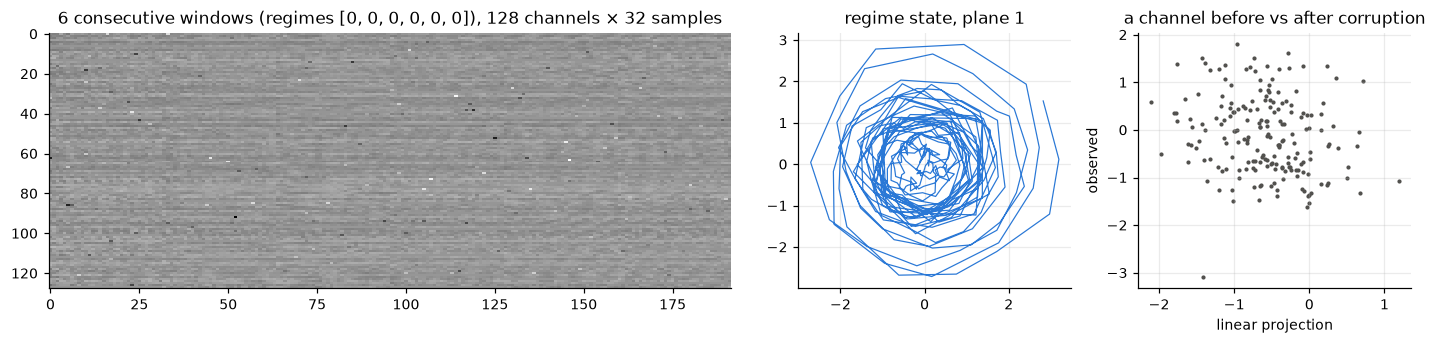

In [16]:
spec = BigSpec()
rng = np.random.default_rng(spec.seed)
t0 = time.time()
train_lat = simulate_big(spec, SERIES[0], T_WIN, rng)
test_lat = simulate_big(spec, SERIES[1], T_WIN, rng)
print(f"simulated in {time.time()-t0:.0f}s: train {train_lat['u'].shape}, test {test_lat['u'].shape}")
corr = Corruptor(spec).to(DEVICE)
U_tr = torch.tensor(train_lat["u"], device=DEVICE); LG_tr = torch.tensor(train_lat["logg"], device=DEVICE)
with torch.no_grad():                                   # channel standardisation from a training sample
    i = torch.randint(SERIES[0], (2048,)); t = torch.randint(T_WIN, (2048,))
    o = corr(U_tr[i, t], LG_tr[i, t])
    corr.mu.copy_(o.mean((0, 1))); corr.sd.copy_(o.std((0, 1)) + 1e-6)

def render_test(lat, idx_series, idx_t, chunk=0):
    """Deterministic rendering of test windows (CPU generator seeded by chunk)."""
    g = torch.Generator().manual_seed(10_000 + chunk)
    u = torch.tensor(lat["u"][idx_series, idx_t]); lg = torch.tensor(lat["logg"][idx_series, idx_t])
    corr_cpu = corr.to("cpu")
    with torch.no_grad():
        o = corr_cpu(u, lg, gen=g)
    corr.to(DEVICE)
    return o

# what the encoder sees
o = render_test(test_lat, np.zeros(6, int), np.arange(6))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[3, 1.2, 1.2]))
axs[0].imshow(o.reshape(-1, spec.D).T.numpy(), aspect="auto", cmap="Greys", interpolation="nearest")
axs[0].set_title(f"6 consecutive windows (regimes {test_lat['S'][0,:6].tolist()}), 128 channels × 32 samples"); axs[0].grid(False)
xs = test_lat["x"][0, :200].reshape(-1, 6)
axs[1].plot(xs[:400, 0], xs[:400, 1], lw=0.8, color=C_SH); axs[1].set_title("regime state, plane 1")
on = torch.tensor(test_lat["u"][0, :6]).reshape(-1, spec.n_lat) @ corr.P.cpu().T
axs[2].scatter(on[:, 0], o.reshape(-1, spec.D)[:, corr.perms[0][0]], s=3, color=C_TH)
axs[2].set_title("a channel before vs after corruption"); axs[2].set_xlabel("linear projection"); axs[2].set_ylabel("observed")
plt.tight_layout(); plt.show()

### What the data look like, and how much regime structure survives the corruption
Top: 16 windows of one series: regime, the clean latent factors, and the 128 observed channels. Bottom: regimes 1–3 share their pooled spectrum (same frequencies, different planes); per-window log-spectra of the top 12 PCA components separate them with a held-out supervised LDA at 0.98, and without labels a GMM on the spectra of 6 PCs reaches 0.88. The regime is therefore recoverable from the observations; what the JEPA keeps is a separate question.

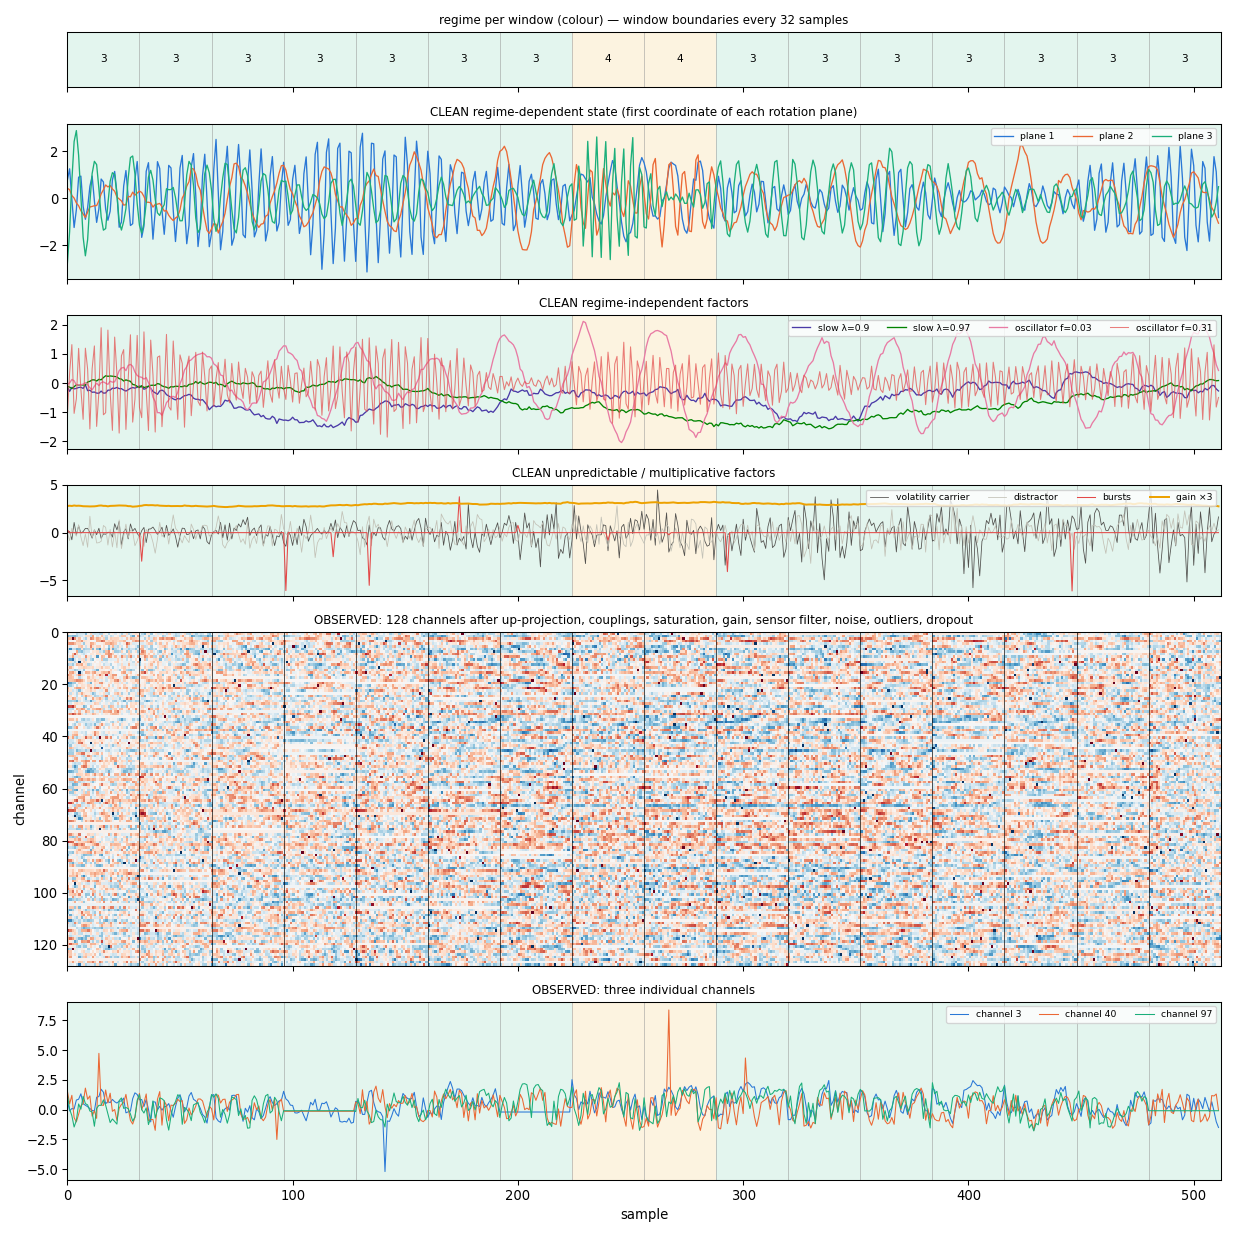

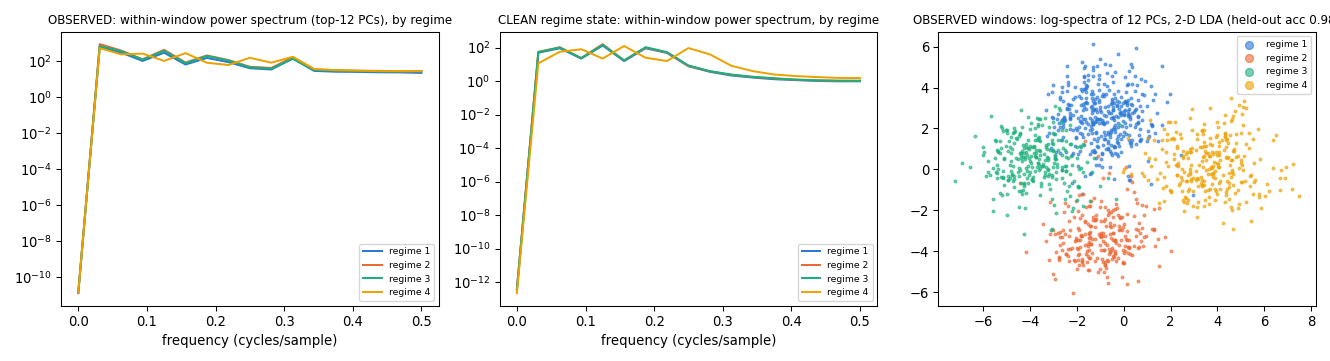

## Model, training and readouts

In [17]:
class BigTCN(nn.Module):
    def __init__(self, D, H, levels=5, k=3):
        super().__init__()
        self.inp = nn.Conv1d(D, H, 1)
        self.blocks = nn.ModuleList([nn.Sequential(
            nn.Conv1d(H, H, k, dilation=2 ** i, padding=2 ** i), nn.GroupNorm(8, H), nn.GELU(),
            nn.Conv1d(H, H, k, dilation=2 ** i, padding=2 ** i)) for i in range(levels)])
        self.out_dim = 2 * H

    def forward(self, x):
        h = self.inp(x.transpose(1, 2))
        for b in self.blocks:
            h = h + b(F.gelu(h))
        h = F.gelu(h)
        return torch.cat([h.mean(-1), h.amax(-1)], -1)


class BigEncoder(nn.Module):
    def __init__(self, D, d, H):
        super().__init__()
        self.phi = BigTCN(D, H)
        self.proj = nn.Sequential(nn.Linear(self.phi.out_dim, 2 * H), nn.BatchNorm1d(2 * H), nn.GELU(), nn.Linear(2 * H, d))

    def forward(self, x):
        return self.proj(self.phi(x))


class BigJEPA(nn.Module):
    def __init__(self, design, d=EMBED_DIM, H=HIDDEN, predictor="linear"):
        super().__init__()
        self.design = design
        self.ctx = BigEncoder(spec.D, d, H)
        self.tgt = self.ctx if design == "shared" else BigEncoder(spec.D, d, H)
        self.pred = nn.Linear(d, d, bias=False) if predictor == "linear" else nn.Sequential(
            nn.Linear(d, 512), nn.GELU(), nn.Linear(512, d))
        self.sigreg = SIGReg()

    def losses(self, xc, xn):
        if self.design == "shared":
            out = self.ctx(torch.cat([xc, xn])); z, y = out.chunk(2); reg = self.sigreg(out[None])
        else:
            z, y = self.ctx(xc), self.tgt(xn); reg = 0.5 * (self.sigreg(z[None]) + self.sigreg(y[None]))
        return (y - self.pred(z)).square().mean(), reg

In [18]:
EVAL_S, EVAL_T = np.repeat(np.arange(SERIES[1]), T_WIN), np.tile(np.arange(T_WIN), SERIES[1])
test_feats = window_features(spec, test_lat)

@torch.no_grad()
def encode_test(fn, n_series=None, chunk=2000):
    """Encode test windows of the first n_series test series (all windows, in order) -> (n, T, d) arrays."""
    n_series = n_series or SERIES[1]
    outs = []
    sel = np.arange(n_series * T_WIN)
    for c, i in enumerate(range(0, len(sel), chunk)):
        j = sel[i: i + chunk]
        o = render_test(test_lat, EVAL_S[j], EVAL_T[j], chunk=c).to(DEVICE)
        outs.append([a.cpu().numpy().astype(np.float64) for a in fn(o)])
    return [np.concatenate([o[k] for o in outs]).reshape(n_series, T_WIN, -1) for k in range(len(outs[0]))]

def quick_eval(model, n_series=4):
    n_series = min(n_series, SERIES[1])
    model.eval()
    Z, Y = encode_test(lambda o: (model.ctx(o), model.tgt(o)), n_series)
    model.train()
    score, sv = predictable_variance(Z, Y, model.design == "shared")
    Zf, S = Z.reshape(-1, Z.shape[-1]), test_lat["S"][:n_series].reshape(-1)
    n = len(S) // 2
    sc = StandardScaler().fit(Zf[:n])
    lin = LogisticRegression(max_iter=1000, C=0.1).fit(sc.transform(Zf[:n]), S[:n])
    return dict(score=score, top_canon=float(sv[0]), lin_probe=balanced_accuracy_score(S[n:], lin.predict(sc.transform(Zf[n:]))))

def train_big(design, predictor="linear", steps=STEPS, seed=0, tag=None):
    tag = tag or f"{design}_{predictor}_d{EMBED_DIM}"
    path = f"{OUT}/{tag}.pt"
    model = BigJEPA(design, predictor=predictor).to(DEVICE)
    if os.path.exists(path):
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); model.eval()
        print(f"loaded {path}")
        return model, ck["curve"]
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=steps, pct_start=0.05)
    curve, t0 = [], time.time()
    for step in range(steps + 1):
        if step % EVAL_EVERY == 0:
            ev = quick_eval(model)
            curve.append(dict(step=step, **ev, pred=float(pred) if step else np.nan, reg=float(rg) if step else np.nan))
            msg = (f"[{tag}] step {step:6d}  {time.time()-t0:6.0f}s  score {ev['score']:.2f}  "
                   f"lin-probe {ev['lin_probe']:.3f}  top canon {ev['top_canon']:.3f}")
            print(msg, flush=True)
            with open(f"{OUT}/progress.log", "a") as f:   # follow with: tail -f large_scale_runs/progress.log
                f.write(time.strftime("%H:%M:%S ") + msg + "\n")
        if step == steps:
            break
        i = torch.randint(SERIES[0], (BATCH,), device=DEVICE); t = torch.randint(T_WIN - 1, (BATCH,), device=DEVICE)
        with torch.no_grad():
            xc, xn = corr(U_tr[i, t], LG_tr[i, t]), corr(U_tr[i, t + 1], LG_tr[i, t + 1])
        pred, rg = model.losses(xc, xn)
        loss = pred + LAM * rg
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step(); sched.step()
    model.eval()
    torch.save(dict(model=model.state_dict(), curve=curve), path)
    return model, curve

def regime_report(Z, Y=None, name="", n_eval=16000, seed=0):
    """Regime recoverability from a latent (and, for separate encoders, from the pair on the same input)."""
    N, T, d = Z.shape
    S = test_lat["S"][:N]
    take = min(N * T, n_eval)
    Zf, Sf = Z.reshape(-1, d)[:take], S.reshape(-1)[:take]           # keep temporal order for smoothing
    n = int(0.6 * take)
    sc = StandardScaler().fit(Zf[:n]); Zs = sc.transform(Zf)
    K = spec.K
    r = dict(latent=name)
    lin = LogisticRegression(max_iter=2000, C=0.1).fit(Zs[:n], Sf[:n])
    r["linear probe"] = balanced_accuracy_score(Sf[n:], lin.predict(Zs[n:]))
    mlp = MLPClassifier((256, 256), max_iter=200, early_stopping=True, random_state=seed).fit(Zs[:n], Sf[:n])
    r["MLP probe"] = balanced_accuracy_score(Sf[n:], mlp.predict(Zs[n:]))
    from sklearn.decomposition import PCA
    for k in [8, 32]:
        pcs = PCA(min(k, d), random_state=seed).fit(Zs[:n]).transform(Zs)
        gm = GaussianMixture(K, n_init=3, random_state=seed).fit(pcs[:n])
        r[f"GMM on PCA-{k}"] = best_perm_acc(Sf[n:], gm.predict(pcs[n:]), K)
        if k == 8:   # unsupervised + temporal smoothing of the posteriors over ±2 windows (change-point style)
            post = gm.predict_proba(pcs[n:])
            sm = np.stack([np.convolve(post[:, j], np.ones(5) / 5, mode="same") for j in range(K)], 1)
            r["GMM PCA-8 + smoothing"] = best_perm_acc(Sf[n:], sm.argmax(1), K)
    if Y is not None:
        Yf = Y.reshape(-1, d)[:take]; Ys = StandardScaler().fit(Yf[:n]).transform(Yf)
        from sklearn.cross_decomposition import CCA
        cca = CCA(8, max_iter=1000).fit(Zs[:n], Ys[:n])
        a, b = cca.transform(Zs[n:], Ys[n:])
        r["switch-reg on top-8 CCA(Z,Y)"] = best_perm_acc(Sf[n:], switching_regression(a, b, K, seed=seed), K)
        mlp = MLPClassifier((256, 256), max_iter=200, early_stopping=True, random_state=seed).fit(np.c_[Zs, Ys][:n], Sf[:n])
        r["MLP probe (Z,Y)"] = balanced_accuracy_score(Sf[n:], mlp.predict(np.c_[Zs, Ys][n:]))
    r.update({f"clu {k}": v for k, v in cluster_battery(Z, S, K, Y, seed=seed).items()})
    return r

def r2_by_type(Z, name, n_eval=16000):
    N = Z.shape[0]
    feats = {k: v[:N].reshape(N * T_WIN, -1)[:n_eval][None] for k, v in test_feats.items()}
    out = r2_table(Z.reshape(-1, Z.shape[-1])[:n_eval][None], feats, int(0.6 * min(n_eval, N * T_WIN)))
    return dict(latent=name, **out)

## Theory reference
The window-level autocorrelations give the §7 ranking. The count says whether the regime indicator should fit in
124 dimensions behind the slow regime-free monomials. The oracle (optimal linear encoders on a degree-≤2 window-level
dictionary) is only a reference: the learnt encoder sees 32 samples per window, far richer than that dictionary.

In [19]:
# Approximate theory reference. Window-level autocorrelations of the feature types, and the §7 count of regime-free
# slow monomials that are at least as predictable as the regime indicator.
P = np.full((spec.K, spec.K), (1 - spec.p_stay) / (spec.K - 1)); np.fill_diagonal(P, spec.p_stay)
theta = float(sorted(abs(np.linalg.eigvals(P)))[-2])
slow_like = dict(**{f"slow λ={l}": l for l in spec.slow_lams}, **{"log-vol": spec.vol_lam, "gain drift": spec.gain_lam})
costs = -np.log(np.array(list(slow_like.values())))
def count_monomials(costs, budget):
    cnt = 0
    def rec(i, left):
        nonlocal cnt
        if i == len(costs):
            cnt += 1; return
        k = 0
        while k * costs[i] <= left + 1e-12:
            rec(i + 1, left - k * costs[i]); k += 1
    rec(0, budget)
    return cnt - 1
n_ahead = count_monomials(costs, -np.log(theta))
print(f"regime indicator autocorrelation θ = {theta:.3f}")
print(f"window-level autocorrelation of x_end in regime k: {[round(r ** spec.W, 3) for r in spec.reg_damp]}")
print(f"oscillators (window level): |λ| = {spec.osc_damp ** spec.W:.3f}")
print(f"§7 count: monomials of the slow/vol/gain factors with autocorrelation ≥ θ: {n_ahead} (< d={EMBED_DIM}: the "
      f"regime indicator should {'fit' if n_ahead < EMBED_DIM else 'NOT fit'} in the latent)")

# Oracle on a window-level dictionary (degree ≤ 2 of the window features, × regime indicators): which feature types
# the optimal linear encoders keep at d = EMBED_DIM. It ignores sample-level structure, so it is a reference only.
ORC_SERIES = min(24, SERIES[0])
orc_lat = {k: v[:ORC_SERIES] for k, v in train_lat.items()}

def oracle_big(d):
    f = window_features(spec, orc_lat)
    base = np.concatenate([f[k] for k in ["regime state x", "state energy per plane", "slow factors", "oscillators",
                                          "log-volatility", "gain drift"]], -1)
    nv = base.shape[-1]
    monos = [base[..., i] for i in range(nv)] + [base[..., i] * base[..., j] for i in range(nv) for j in range(i, nv)]
    monos = np.stack(monos, -1)
    oh = np.eye(spec.K)[orc_lat["S"]]
    Phi = np.concatenate([oh[..., : spec.K - 1]] + [monos * oh[..., k: k + 1] for k in range(spec.K)], -1)
    Kmat, Pw = oracle_K(Phi)
    Uk, sk, Vkt = np.linalg.svd(Kmat)
    f_sh, U, lo, up = shared_optimum(Kmat, d, iters=150)
    return dict(K=Kmat, Pw=Pw, sep=(Pw @ Vkt[:d].T, Pw @ Uk[:, :d]), sh=Pw @ U, sk=sk,
                score_sep=float((sk[:d] ** 2).sum()), score_sh=f_sh, bracket=(lo, up))

t0 = time.time()
orc = oracle_big(EMBED_DIM)
print(f"oracle ({orc['Pw'].shape[-1]} whitened features, {time.time()-t0:.0f}s): separate score {orc['score_sep']:.2f}, "
      f"shared {orc['score_sh']:.2f} (bracket {orc['bracket'][0]:.2f}–{orc['bracket'][1]:.2f})")
_tf = test_feats
test_feats = window_features(spec, orc_lat)            # oracle latents live on the training simulation
_tl = test_lat; test_lat = orc_lat
orc_r2 = pd.DataFrame([r2_by_type(orc["sh"], "theory shared"), r2_by_type(orc["sep"][0], "theory separate (Z)")])
orc_reg = pd.DataFrame([regime_report(orc["sh"], name="theory shared"),
                        regime_report(orc["sep"][0], orc["sep"][1], name="theory separate")])
test_feats, test_lat = _tf, _tl
display(orc_r2.round(3)); display(orc_reg.round(3))

regime indicator autocorrelation θ = 0.867
window-level autocorrelation of x_end in regime k: [0.725, 0.725, 0.725, 0.377]
oscillators (window level): |λ| = 0.852
§7 count: monomials of the slow/vol/gain factors with autocorrelation ≥ θ: 62 (< d=124: the regime indicator should fit in the latent)
oracle (759 whitened features, 13s): separate score 88.34, shared 86.45 (bracket 83.50–88.34)


KeyboardInterrupt: 

## Baselines

In [ ]:
# Baselines: (1) hand-crafted window statistics of the raw observations, (2) the same encoder at random init,
# (3) a supervised ceiling: the same backbone trained with regime labels.
def raw_stats(o):
    m, s = o.mean(1), o.std(1)
    oc = o - o.mean(1, keepdim=True)
    ac1 = (oc[:, 1:] * oc[:, :-1]).mean(1) / (s ** 2 + 1e-6)
    ac2 = (oc[:, 2:] * oc[:, :-2]).mean(1) / (s ** 2 + 1e-6)
    return (torch.cat([m, s, ac1, ac2], -1),)

(R,) = encode_test(raw_stats)
Rf = R.reshape(-1, R.shape[-1])
R = PCA(EMBED_DIM, random_state=0).fit(Rf[:8000]).transform(Rf).reshape(R.shape[0], R.shape[1], -1)
torch.manual_seed(0)
rand_model = BigJEPA("separate").to(DEVICE).eval()
(Zr,) = encode_test(lambda o: (rand_model.ctx(o),))

def train_supervised(steps=3000 if not FAST else 500):
    path = f"{OUT}/supervised.pt"
    enc = BigEncoder(spec.D, spec.K, HIDDEN).to(DEVICE)
    S_tr = torch.tensor(train_lat["S"], device=DEVICE)
    if os.path.exists(path):
        enc.load_state_dict(torch.load(path, map_location=DEVICE)); return enc.eval()
    opt = torch.optim.AdamW(enc.parameters(), lr=LR)
    for step in range(steps):
        i = torch.randint(SERIES[0], (BATCH,), device=DEVICE); t = torch.randint(T_WIN, (BATCH,), device=DEVICE)
        with torch.no_grad():
            x = corr(U_tr[i, t], LG_tr[i, t])
        loss = F.cross_entropy(enc(x), S_tr[i, t])
        opt.zero_grad(); loss.backward(); opt.step()
    torch.save(enc.state_dict(), path)
    return enc.eval()

sup = train_supervised()
(L,) = encode_test(lambda o: (sup(o),))
n_all = min(16000, SERIES[1] * T_WIN); n0 = int(0.6 * n_all)
sup_acc = balanced_accuracy_score(test_lat["S"].reshape(-1)[n0:n_all], L.reshape(-1, spec.K)[n0:n_all].argmax(1))
base = pd.DataFrame([regime_report(R, name="raw window statistics (PCA-124)"),
                     regime_report(Zr, name="random-init encoder")])
display(base.round(3))
print(f"supervised ceiling (same backbone, trained on labels): balanced accuracy {sup_acc:.3f}")

,latent,linear probe,MLP probe,GMM on PCA-8,GMM PCA-8 + smoothing,GMM on PCA-32,clu GMM,clu spectral kNN,clu subspace (TSC),clu HMM,clu AR-HMM (z_t→z_t+1)
0,raw window statistics (PCA-124),0.874,0.858,0.288,0.282,0.298,0.308,0.330,0.311,0.345,0.314
1,random-init encoder,0.494,0.455,0.267,0.266,0.271,0.279,0.281,0.279,0.284,0.274


supervised ceiling (same backbone, trained on labels): balanced accuracy 1.000


## Long training
Checkpoints are saved to `large_scale_runs/`. Re-running the notebook loads them instead of retraining. A learning
curve is logged every `EVAL_EVERY` steps.

In [13]:
models, curves = {}, {}
for design in ["shared", "separate"]:
    models[design], curves[design] = train_big(design)

[shared_linear_d124] step      0       3s  score 7.01  lin-probe 0.461  top canon 0.940
[shared_linear_d124] step   2000     277s  score 56.08  lin-probe 0.256  top canon 0.978
[shared_linear_d124] step   4000     552s  score 58.97  lin-probe 0.253  top canon 0.980
[shared_linear_d124] step   6000     822s  score 60.97  lin-probe 0.258  top canon 0.982
[shared_linear_d124] step   8000    1092s  score 61.54  lin-probe 0.249  top canon 0.984
[shared_linear_d124] step  10000    1360s  score 62.07  lin-probe 0.254  top canon 0.985
[shared_linear_d124] step  12000    1632s  score 62.60  lin-probe 0.265  top canon 0.985
[shared_linear_d124] step  14000    1900s  score 62.63  lin-probe 0.267  top canon 0.985
[shared_linear_d124] step  16000    2171s  score 62.56  lin-probe 0.267  top canon 0.985
[shared_linear_d124] step  18000    2436s  score 62.52  lin-probe 0.270  top canon 0.985
[shared_linear_d124] step  20000    2707s  score 62.54  lin-probe 0.267  top canon 0.985
[separate_linear_d124]

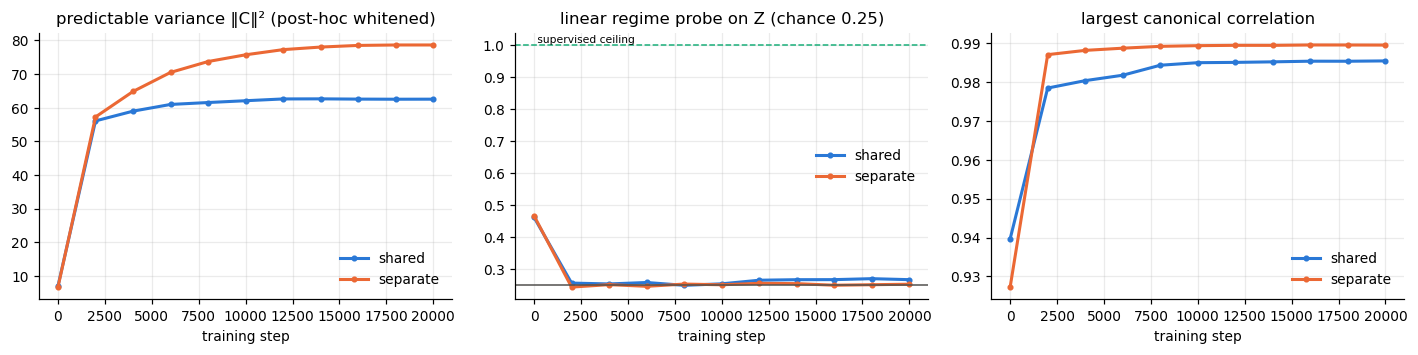

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3))
for des, c in [("shared", C_SH), ("separate", C_SEP)]:
    cv = pd.DataFrame(curves[des])
    axs[0].plot(cv.step, cv.score, "o-", color=c, label=des, ms=3)
    axs[1].plot(cv.step, cv.lin_probe, "o-", color=c, label=des, ms=3)
    axs[2].plot(cv.step, cv.top_canon, "o-", color=c, label=des, ms=3)
axs[1].axhline(1 / spec.K, color=C_TH, lw=1); axs[1].axhline(sup_acc, color=C_B, lw=1, ls="--")
axs[1].text(0, sup_acc, " supervised ceiling", fontsize=7, va="bottom")
for a, t in zip(axs, ["predictable variance ‖C‖² (post-hoc whitened)", "linear regime probe on Z (chance 0.25)",
                      "largest canonical correlation"]):
    a.set_title(t); a.set_xlabel("training step"); a.legend(frameon=False)
plt.tight_layout(); plt.show()

### Training losses and how close the latent is to whitened
Single-batch losses at the checkpoints. Dashed lines: SIGReg of exactly N(0, I) batches (≈ 1.06), the best a batch can score. The shared encoder's SIGReg stays near 2× that and 56 of its 124 latent directions have variance < 0.1: it lowers the prediction loss by **shrinking** directions, which exact whitening forbids (§8). The separate encoders reach the Gaussian reference and keep ~100 active directions.

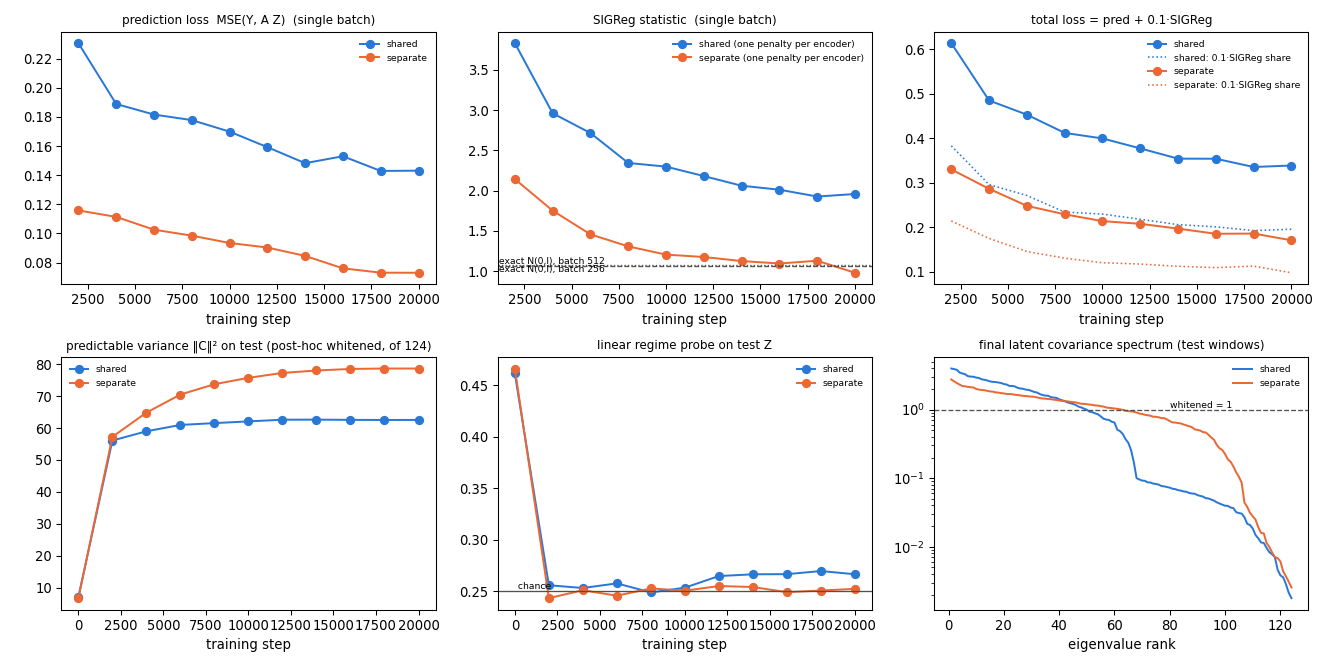

## Final evaluation

In [15]:
lat_final = {}
for des, m in models.items():
    lat_final[des] = encode_test(lambda o, m=m: (m.ctx(o), m.tgt(o)))
rows_r2 = [r2_by_type(R, "raw statistics"), r2_by_type(Zr, "random-init encoder")]
rows_reg = list(base.to_dict("records"))
for des, (Z, Y) in lat_final.items():
    rows_r2.append(r2_by_type(Z, f"{des} Z"))
    if des == "separate":
        rows_r2.append(r2_by_type(Y, "separate Y"))
    rows_reg.append(regime_report(Z, Y if des == "separate" else None, name=f"learnt {des}"))
    sc, sv = predictable_variance(Z, Y, des == "shared")
    print(f"{des}: predictable variance {sc:.2f} over d={EMBED_DIM}; canonical correlations > 0.5: {(sv > 0.5).sum()}")
print("\nLinear R² of each ground-truth feature type (what the latent kept):")
display(pd.concat([pd.DataFrame(rows_r2), orc_r2]).set_index("latent").round(3))
print(f"\nRegime recoverability (balanced accuracy, chance {1/spec.K:.2f}; supervised ceiling {sup_acc:.3f}):")
reg_table = pd.concat([pd.DataFrame(rows_reg), orc_reg]).set_index("latent")
display(reg_table.round(3))

shared: predictable variance 62.58 over d=124; canonical correlations > 0.5: 76
separate: predictable variance 78.59 over d=124; canonical correlations > 0.5: 96

Linear R² of each ground-truth feature type (what the latent kept):


,regime indicator,regime state x,g = x·1[S=k],state energy per plane,slow factors,slow factors²,oscillators,log-volatility,gain drift,distractors
latent,,,,,,,,,,
raw statistics,0.551,0.123,0.061,0.583,0.917,0.494,0.023,0.376,0.897,0.727
random-init encoder,0.152,0.034,0.016,0.284,0.898,0.375,0.212,0.191,0.752,0.289
shared Z,0.000,0.000,0.000,0.000,0.969,0.811,0.915,0.850,0.975,0.000
separate Z,0.000,0.346,0.088,0.027,0.955,0.835,0.926,0.000,0.973,0.000
separate Y,0.000,0.000,0.000,0.000,0.949,0.817,0.712,0.000,0.966,0.000
theory shared,0.987,0.000,0.000,0.000,0.999,0.997,0.991,0.999,1.000,0.000
theory separate (Z),0.971,0.076,0.015,0.574,0.998,0.992,0.980,0.998,0.999,0.000



Regime recoverability (balanced accuracy, chance 0.25; supervised ceiling 1.000):


,linear probe,MLP probe,GMM on PCA-8,GMM PCA-8 + smoothing,GMM on PCA-32,clu GMM,clu spectral kNN,clu subspace (TSC),clu HMM,clu AR-HMM (z_t→z_t+1),"switch-reg on top-8 CCA(Z,Y)","MLP probe (Z,Y)",clu HMM switch-reg (Z→Y)
latent,,,,,,,,,,,,,
raw window statistics (PCA-124),0.874,0.858,0.288,0.282,0.298,0.308,0.330,0.311,0.345,0.314,NaN,NaN,NaN
random-init encoder,0.494,0.455,0.267,0.266,0.271,0.279,0.281,0.279,0.284,0.274,NaN,NaN,NaN
learnt shared,0.241,0.256,0.261,0.264,0.279,0.279,0.273,0.277,0.272,0.273,NaN,NaN,NaN
learnt separate,0.259,0.272,0.264,0.262,0.271,0.273,0.269,0.300,0.268,0.289,0.267,0.260,0.285
theory shared,1.000,0.992,0.718,0.714,0.999,0.692,0.518,1.000,0.691,0.599,NaN,NaN,NaN
theory separate,1.000,0.997,0.668,0.659,0.998,0.763,0.740,1.000,0.829,0.616,0.264,0.994,0.719


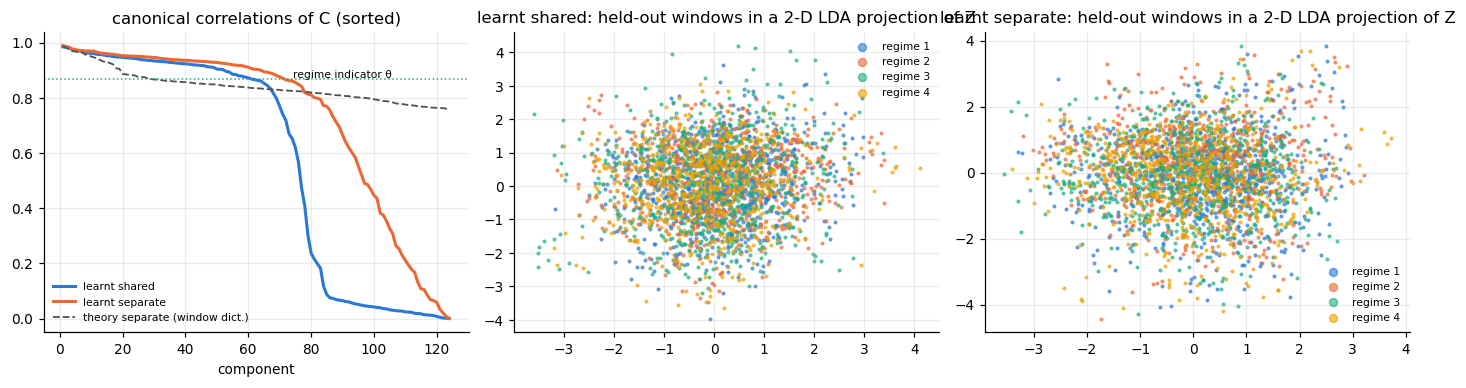

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for des, c in [("shared", C_SH), ("separate", C_SEP)]:
    Z, Y = lat_final[des]
    _, sv = predictable_variance(Z, Y, des == "shared")
    axs[0].plot(np.arange(1, len(sv) + 1), sv, color=c, label=f"learnt {des}")
axs[0].plot(np.arange(1, EMBED_DIM + 1), orc["sk"][:EMBED_DIM], "--", color=C_TH, lw=1.2, label="theory separate (window dict.)")
axs[0].axhline(theta, color=C_B, lw=1, ls=":"); axs[0].text(EMBED_DIM * 0.6, theta, "regime indicator θ", fontsize=7, va="bottom")
axs[0].set_title("canonical correlations of C (sorted)"); axs[0].set_xlabel("component"); axs[0].legend(frameon=False, fontsize=7)
n_l = min(6000, SERIES[1] * T_WIN); h_l = n_l // 2
S_ = test_lat["S"].reshape(-1)[:n_l]
pal = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
for a, des in zip(axs[1:], ["shared", "separate"]):
    Zf = StandardScaler().fit_transform(lat_final[des][0].reshape(-1, EMBED_DIM)[:n_l])
    lda = LinearDiscriminantAnalysis(n_components=2).fit(Zf[:h_l], S_[:h_l]).transform(Zf[h_l:])
    for k in range(spec.K):
        a.scatter(*lda[S_[h_l:] == k].T, s=3, color=pal[k], label=f"regime {k+1}", alpha=.6)
    a.set_title(f"learnt {des}: held-out windows in a 2-D LDA projection of Z"); a.legend(frameon=False, fontsize=7, markerscale=3)
plt.tight_layout(); plt.show()

### PCA and t-SNE of the latents on test windows, coloured by regime
4000 windows from two test series. Only the supervised encoder separates the regimes; the JEPA latents mix them globally. The short single-coloured strands in the JEPA t-SNE are runs of *consecutive* windows (slow features make neighbouring windows close and regimes last ~10 windows), not regime clusters.

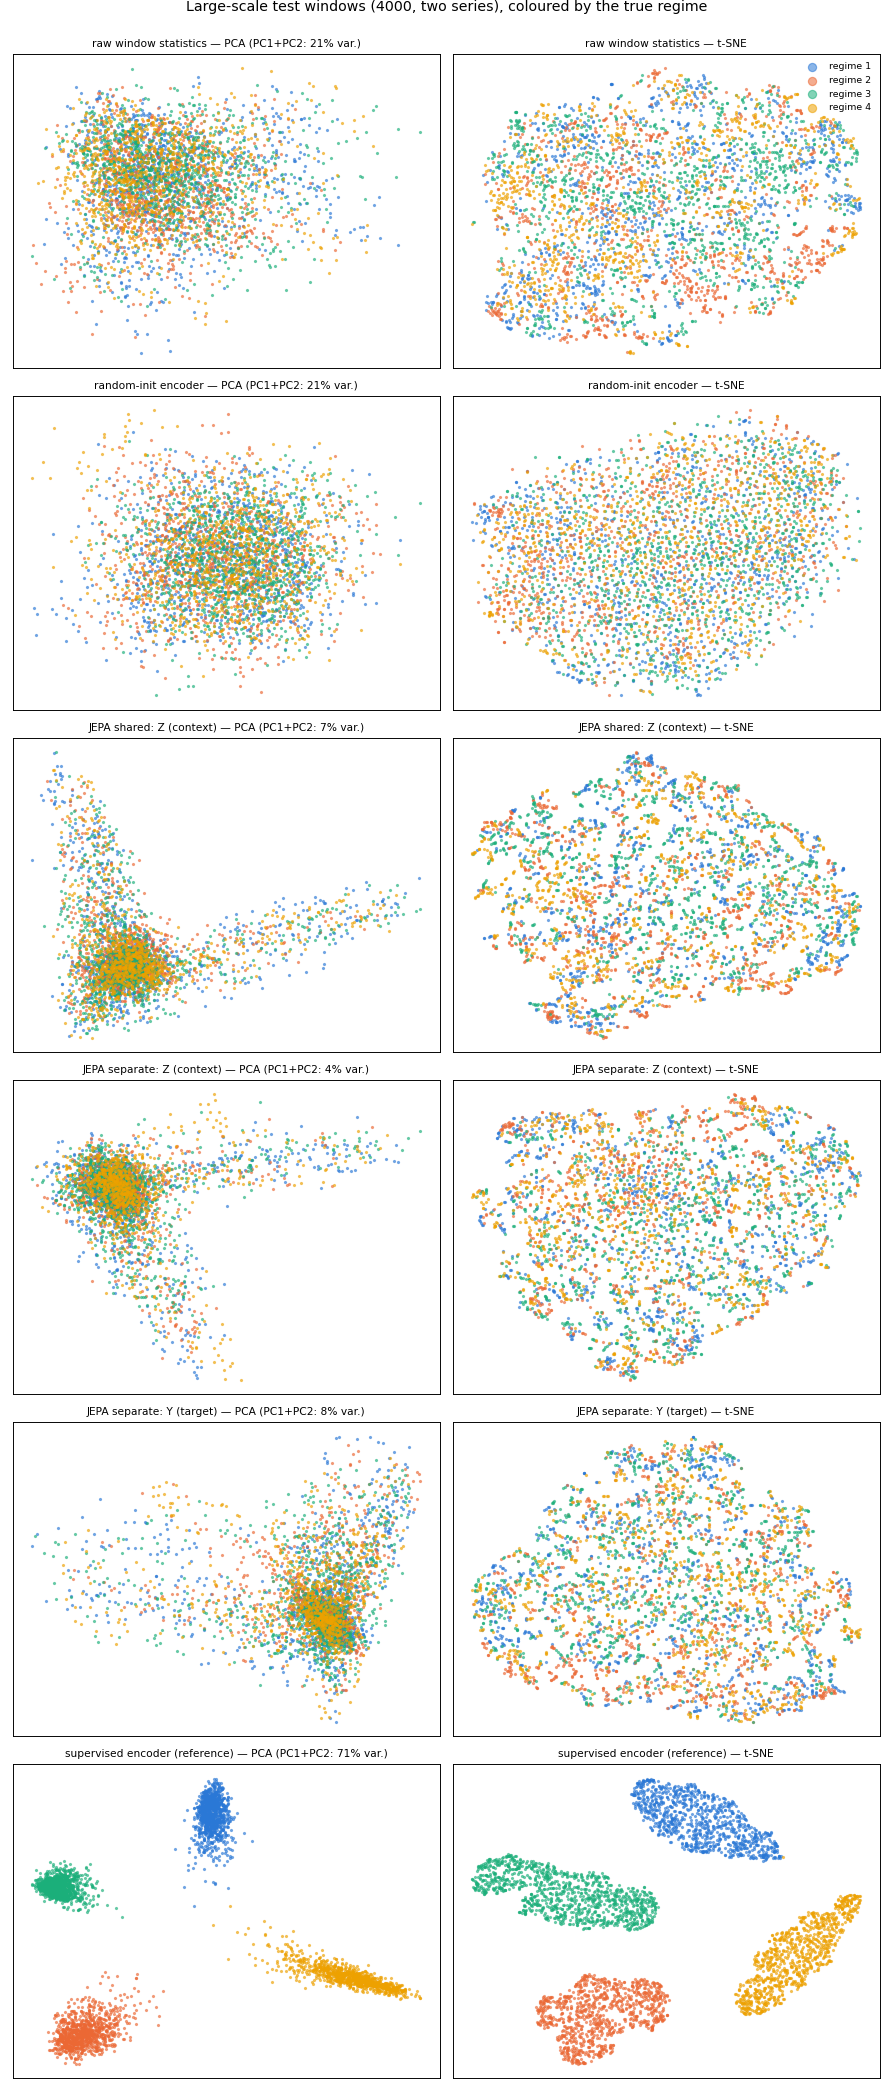

## Verdict

In [17]:
rt = reg_table
best = lambda name: rt.loc[name, ["linear probe", "MLP probe"]].max()
for des in ["shared", "separate"]:
    print(f"{des}: best probe {best('learnt '+des):.3f} vs raw stats {best('raw window statistics (PCA-124)'):.3f}, "
          f"random encoder {best('random-init encoder'):.3f}, supervised ceiling {sup_acc:.3f}; "
          f"unsupervised GMM(PCA-8)+smoothing {rt.loc['learnt '+des, 'GMM PCA-8 + smoothing']:.3f}")
verdict = pd.DataFrame([
    dict(question="regime recoverable from the learnt latent (probe ≥ 0.9 × supervised ceiling)?",
         **{des: bool(best('learnt ' + des) >= 0.9 * sup_acc) for des in ["shared", "separate"]}),
    dict(question="better than the untrained encoder and raw statistics?",
         **{des: bool(best('learnt ' + des) > max(best('raw window statistics (PCA-124)'), best('random-init encoder')) + 0.02) for des in ["shared", "separate"]}),
    dict(question="recoverable without labels (GMM on PCA-8 + smoothing ≥ 0.8)?",
         **{des: bool(rt.loc['learnt ' + des, 'GMM PCA-8 + smoothing'] >= 0.8) for des in ["shared", "separate"]}),
    dict(question="regime-free unpredictable distractors excluded (R² < 0.1)?",
         **{des: bool(pd.DataFrame(rows_r2).set_index('latent').loc[f'{des} Z', 'distractors'] < 0.1) for des in ["shared", "separate"]}),
])
display(verdict)

shared: best probe 0.256 vs raw stats 0.874, random encoder 0.494, supervised ceiling 1.000; unsupervised GMM(PCA-8)+smoothing 0.264
separate: best probe 0.272 vs raw stats 0.874, random encoder 0.494, supervised ceiling 1.000; unsupervised GMM(PCA-8)+smoothing 0.262


,question,shared,separate
0,regime recoverable from the learnt latent (pro...,False,False
1,better than the untrained encoder and raw stat...,False,False
2,recoverable without labels (GMM on PCA-8 + smo...,False,False
3,regime-free unpredictable distractors excluded...,True,True
